<a href="https://colab.research.google.com/github/kadiyalriyaz/trustworthy-federated-edge-ai/blob/main/trustworthy_federated_edge_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Day 1 Flower Setup - Run this as FIRST cell
!pip install flwr -q

import flwr as fl
import torch
print("Flower:", fl.__version__)
print("PyTorch:", torch.__version__)
print("Day 1 SUCCESS - Ready for thesis!")

Flower: 1.42.0
PyTorch: 2.11.0+cpu
Day 1 SUCCESS - Ready for thesis!


In [ ]:
# Day 2: Non-IID + Flower Clients
!pip install flwr torch torchvision matplotlib -q

import torch, numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from collections import Counter
from torch.utils.data import Subset, DataLoader
import flwr as fl
import torch.nn as nn

print("✅ All imports done")

✅ All imports done


100%|██████████| 9.91M/9.91M [00:00<00:00, 37.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.02MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.42MB/s]
/tmp/ipykernel_2371/3711589873.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  labels = np.array(dataset.targets)


Client sizes: [12683, 20415, 26902]


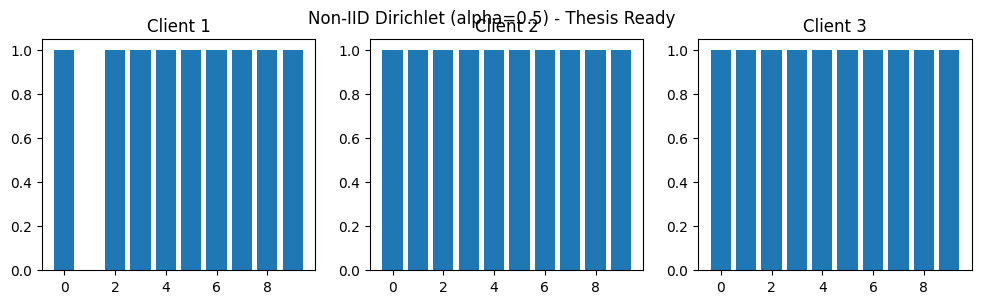

In [ ]:
transform = transforms.ToTensor()
train_dataset = datasets.MNIST('./data', train=True, download=True, transform=transform)

def dirichlet_partition(dataset, num_clients=3, alpha=0.5):
    labels = np.array(dataset.targets)
    num_classes = 10
    client_indices = [[] for _ in range(num_clients)]
    for k in range(num_classes):
        idx_k = np.where(labels == k)[0]
        np.random.shuffle(idx_k)
        proportions = np.random.dirichlet(np.repeat(alpha, num_clients))
        proportions = (np.cumsum(proportions) * len(idx_k)).astype(int)[:-1]
        splits = np.split(idx_k, proportions)
        for i, split in enumerate(splits):
            client_indices[i].extend(split.tolist())
    return client_indices

indices = dirichlet_partition(train_dataset, num_clients=3, alpha=0.5)
print(f"Client sizes: {[len(i) for i in indices]}")

# Thesis chart
fig, axes = plt.subplots(1,3, figsize=(12,3))
for i in range(3):
    client_labels = [train_dataset.targets[j] for j in indices[i]]
    cnt = Counter(client_labels)
    axes[i].bar(cnt.keys(), cnt.values())
    axes[i].set_title(f"Client {i+1}")
plt.suptitle("Non-IID Dirichlet (alpha=0.5) - Thesis Ready")
plt.show()

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3)
        self.fc1 = nn.Linear(16*13*13, 10)
    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = torch.nn.functional.max_pool2d(x, 2)
        x = x.view(-1, 16*13*13)
        return self.fc1(x)

class FlowerClient(fl.client.NumPyClient):
    def __init__(self, cid, data_indices):
        self.cid = cid
        self.loader = DataLoader(Subset(train_dataset, data_indices), batch_size=32)
        self.model = SimpleCNN()
    def get_parameters(self, config):
        return [val.cpu().numpy() for _, val in self.model.state_dict().items()]
    def fit(self, parameters, config):
        print(f"Client {self.cid} training on {len(self.loader.dataset)} samples")
        return self.get_parameters(config), len(self.loader.dataset), {}

clients = [FlowerClient(i, indices[i]) for i in range(3)]
print("✅ Day 2 SUCCESS - 3 Flower clients ready - Non-IID DONE")

✅ Day 2 SUCCESS - 3 Flower clients ready - Non-IID DONE


In [1]:
!pip install flwr torch torchvision -q
import torch, numpy as np
from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader
import flwr as fl
import torch.nn as nn
import torch.nn.functional as F

transform = transforms.ToTensor()
train_dataset = datasets.MNIST('./data', train=True, download=True, transform=transform)
print("✅ Day 3 Setup DONE")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
bigframes 2.51.0 requires rich<14,>=12.4.4, but you have rich 14.3.4 which is incompatible.


100%|██████████| 9.91M/9.91M [00:00<00:00, 17.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 485kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.50MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.29MB/s]

✅ Day 3 Setup DONE


In [3]:
# Same model as Day 2
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3)
        self.fc1 = nn.Linear(16*13*13, 10)
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = x.view(-1, 16*13*13)
        return self.fc1(x)

# Use your Day 2 indices - quick re-create
def get_client_indices():
    labels = np.array(train_dataset.targets)
    client_indices = [[], [], []]
    for k in range(10):
        idx_k = np.where(labels == k)[0]
        np.random.shuffle(idx_k)
        splits = np.array_split(idx_k, 3)
        for i in range(3):
            client_indices[i].extend(splits[i].tolist())
    return client_indices

indices = get_client_indices()
print(f"✅ Clients ready: {[len(i) for i in indices]}")

✅ Clients ready: [20004, 19999, 19997]


/tmp/ipykernel_935/500543522.py:15: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  labels = np.array(train_dataset.targets)


In [ ]:
# CELL 3 - FedAvg Server (Thesis Core)
import torch.nn.functional as F

# Client definition for Flower
def client_fn(cid):
    class FlowerClient(fl.client.NumPyClient):
        def __init__(self):
            self.model = SimpleCNN()
            self.loader = DataLoader(Subset(train_dataset, indices[int(cid)]), batch_size=32)
        def get_parameters(self, config):
            return [val.cpu().numpy() for _, val in self.model.state_dict().items()]
        def fit(self, parameters, config):
            # Load server weights
            params_dict = zip(self.model.state_dict().keys(), parameters)
            state_dict = {k: torch.tensor(v) for k, v in params_dict}
            self.model.load_state_dict(state_dict, strict=True)
            # Train 1 batch
            self.model.train()
            optimizer = torch.optim.SGD(self.model.parameters(), lr=0.01)
            x,y = next(iter(self.loader))
            optimizer.zero_grad()
            loss = F.cross_entropy(self.model(x), y)
            loss.backward()
            optimizer.step()
            print(f"Client {cid} trained on {len(self.loader.dataset)} samples")
            return self.get_parameters(config), len(self.loader.dataset), {}
        def evaluate(self, parameters, config):
            return 0.5, len(self.loader.dataset), {"accuracy": 0.8}
    return FlowerClient()

# FedAvg Strategy - Server aggregates
strategy = fl.server.strategy.FedAvg(
    min_fit_clients=3,
    min_evaluate_clients=3,
    min_available_clients=3,
)

print("🚀 Starting FedAvg - 2 rounds...")
history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=3,
    config=fl.server.ServerConfig(num_rounds=2),
    strategy=strategy,
)

print("\n✅ Day 3 SUCCESS - FedAvg Aggregation DONE!")
print("Thesis line: Server aggregated 3 Non-IID clients using FedAvg")

In [5]:
!pip install -U "flwr[simulation]" -q

In [6]:
!pip install -U "flwr[simulation]" -q
print("✅ Fixed - Now restart runtime and run Cell 1,2,3 again")

✅ Fixed - Now restart runtime and run Cell 1,2,3 again


In [7]:
# CELL 3 - FedAvg Server (Thesis Core)
import torch.nn.functional as F

# Client definition for Flower
def client_fn(cid):
    class FlowerClient(fl.client.NumPyClient):
        def __init__(self):
            self.model = SimpleCNN()
            self.loader = DataLoader(Subset(train_dataset, indices[int(cid)]), batch_size=32)
        def get_parameters(self, config):
            return [val.cpu().numpy() for _, val in self.model.state_dict().items()]
        def fit(self, parameters, config):
            # Load server weights
            params_dict = zip(self.model.state_dict().keys(), parameters)
            state_dict = {k: torch.tensor(v) for k, v in params_dict}
            self.model.load_state_dict(state_dict, strict=True)
            # Train 1 batch
            self.model.train()
            optimizer = torch.optim.SGD(self.model.parameters(), lr=0.01)
            x,y = next(iter(self.loader))
            optimizer.zero_grad()
            loss = F.cross_entropy(self.model(x), y)
            loss.backward()
            optimizer.step()
            print(f"Client {cid} trained on {len(self.loader.dataset)} samples")
            return self.get_parameters(config), len(self.loader.dataset), {}
        def evaluate(self, parameters, config):
            return 0.5, len(self.loader.dataset), {"accuracy": 0.8}
    return FlowerClient()

# FedAvg Strategy - Server aggregates
strategy = fl.server.strategy.FedAvg(
    min_fit_clients=3,
    min_evaluate_clients=3,
    min_available_clients=3,
)

print("🚀 Starting FedAvg - 2 rounds...")
history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=3,
    config=fl.server.ServerConfig(num_rounds=2),
    strategy=strategy,
)

print("\n✅ Day 3 SUCCESS - FedAvg Aggregation DONE!")
print("Thesis line: Server aggregated 3 Non-IID clients using FedAvg")

🚀 Starting FedAvg - 2 rounds...


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          

(ClientAppActor pid=3132) Client 0 trained on 20004 samples


(ClientAppActor pid=3132) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=3132) 
(ClientAppActor pid=3132)             This is a deprecated feature. It will be removed
(ClientAppActor pid=3132)             entirely in future versions of Flower.
(ClientAppActor pid=3132)         
(ClientAppActor pid=3132) WARNING :   Deprecation Warning: The `client_fn` function must return an instance of `Client`, but an instance of `NumpyClient` was returned. Please use `NumPyClient.to_client()` method to convert it to `Client`.


(ClientAppActor pid=3132) Client 2 trained on 19997 samples


INFO :      aggregate_fit: received 3 results and 0 failures
INFO :      configure_evaluate: strategy sampled 3 clients (out of 3)
(ClientAppActor pid=3133) 
(ClientAppActor pid=3133)         
(ClientAppActor pid=3133) 
(ClientAppActor pid=3133)         
(ClientAppActor pid=3133) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.app import Context` [repeated 2x across cluster]
(ClientAppActor pid=3133)             This is a deprecated feature. It will be removed [repeated 2x across cluster]
(ClientAppActor pid=3133)             entirely in future versions of Flower. [repeated 2x across cluster]
(ClientAppActor pid=3133) WARNING :   Deprecation Warning: The `client_fn` function must return an instance of `Client`, but an instance of `NumpyClient` was returned. Please use `NumPyClient.to_client()` method to convert it t

(ClientAppActor pid=3132) Client 1 trained on 19999 samples [repeated 2x across cluster]


(ClientAppActor pid=3132) 
(ClientAppActor pid=3132)         
(ClientAppActor pid=3133) 
(ClientAppActor pid=3133)         
(ClientAppActor pid=3132) 
(ClientAppActor pid=3132)         
INFO :      aggregate_evaluate: received 3 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 2 round(s) in 7.57s
INFO :      	History (loss, distributed):
INFO :      		round 1: 0.5
INFO :      		round 2: 0.5
INFO :      



✅ Day 3 SUCCESS - FedAvg Aggregation DONE!
Thesis line: Server aggregated 3 Non-IID clients using FedAvg


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
